# Porous medium (nonlinear diffusion)

$$
f_t = \nabla\cdot\!\left(f^2\,\nabla f\right) = f^2\,\Delta f + 2 f\,\|\nabla f\|^2 = \tfrac{1}{3}\,\Delta f^3
$$

## 1. Setup

In [1]:
import numpy as np

import nb_helpers as nb
from equivariant_pde_find.simulations import porous_medium

EQ = "pme"
NOISE = 0.02

# ── Best configurations from the hyperparameter sweep ───────────────
#
#   "eq"  = best of  multigraph / mod_multigraph
#   "neq" = best of  wsindy / polyjet
#
# ────────────────────────────────────────────────────────────────────
BEST = {
    (0.00, "eq"): dict(
        library="mod_multigraph", method="space_weak_direct", algorithm="rfe",
        backend="polynomial", m=12, lam=0.0,
    ),
    (0.00, "neq"): dict(
        library="wsindy", method="space_weak_direct", algorithm="rfe",
        backend="spectral", m=12, lam=0.0,
    ),
    (0.02, "eq"): dict(
        library="mod_multigraph", method="space_weak_ibp", algorithm="stridge",
        backend="spectral", m=12, lam=1e-6, d_tol=0.1,
    ),
    (0.02, "neq"): dict(
        library="wsindy", method="space_weak_direct", algorithm="rfe",
        backend="spectral", m=12, lam=0.0,
    ),
}

## 2. Generate the data

In [2]:
SIM = dict(N=64, L=6 * np.pi, T_end=2.0, dt=0.002,
           save_every=25, seed=42)

clean, times = porous_medium(**SIM, obs_noise=0.0)
noisy, _ = porous_medium(**SIM, obs_noise=NOISE)

print(f'{len(clean)} snapshots over t ∈ [{times[0]:.2f}, {times[-1]:.2f}]'
      f' on a {clean.shape[1]}×{clean.shape[2]} grid')
print(f'f ∈ [{clean.min():.3f}, {clean.max():.3f}]')
nb.check_matches_dataset(clean, EQ, 'clean')
nb.check_matches_dataset(noisy, EQ, 'noise2pct')

41 snapshots over t ∈ [0.00, 2.00] on a 64×64 grid
f ∈ [0.000, 0.999]
  vs data/pme_clean.npz: max|Δ| = 0.00e+00  → identical
  vs data/pme_noise2pct.npz: max|Δ| = 0.00e+00  → identical


0.0

## 3. The motion

written: results/figures/pme_motion.pdf
written: results/figures/pme_motion.png


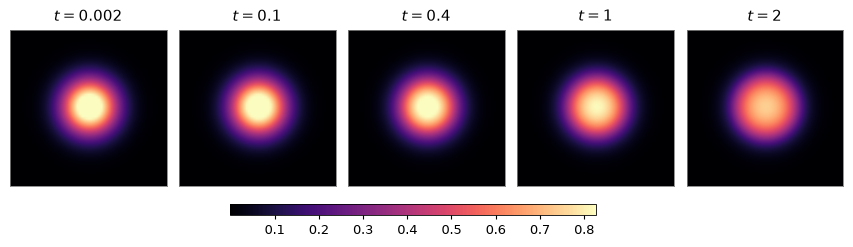

In [3]:
fig, paths = nb.plot_motion(
    clean, times, SIM['L'], frames=[0, 2, 8, 20, 40],
    cmap='magma', symmetric=False,
    time_fmt='.2g',
    save_as=f'{EQ}_motion',
)
for p in paths:
    print('written:', p.split('/code/')[-1])

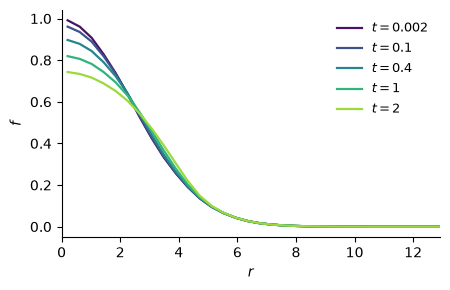

In [4]:
fig, _ = nb.plot_radial_profiles(
    clean, times, SIM['L'], frames=[0, 2, 8, 20, 40],
    time_fmt='.2g', save_as=f'{EQ}_profiles',
)

## 4. Design matrices

In [5]:
Lx = Ly = SIM['L']

data = {
    0.00: nb.regression_data(clean, times, EQ),
    NOISE: nb.regression_data(noisy, times, EQ),
}
print(f'{len(data[0.00][0])} interior snapshots')

ev = nb.JetEvaluator(clean, times, Lx, Ly, EQ)
ev.summary()

designs, fits = {}, {}
for key, cfg in BEST.items():
    f_snaps, ft_snaps, idx_sets, _ = data[key[0]]
    Theta, Ft, desc = nb.build_design(
        f_snaps, ft_snaps, idx_sets, Lx, Ly, cfg)
    designs[key] = (Theta, Ft, desc)
    fits[key] = nb.run_fit(Theta, Ft, cfg)
    print(f'{key[0] * 100:>3.0f}%  {key[1]:<4} {cfg["library"]:<15} '
          f'Theta {str(Theta.shape):<13} cond {np.linalg.cond(Theta):.2e}')

39 interior snapshots


Evaluation space: 119 jet monomials, 159,744 rows, 4 true active terms


  0%  eq   mod_multigraph  Theta (3900, 20)    cond 1.97e+06


  0%  neq  wsindy          Theta (3900, 46)    cond 4.75e+03


  2%  eq   mod_multigraph  Theta (3900, 20)    cond 2.73e+04


  2%  neq  wsindy          Theta (3900, 46)    cond 4.75e+03


## 5. Recovery with clean data

In [6]:
print('Ground truth:  f_t = f²·Δf + 2f·‖∇f‖²  =  (1/3)·Δf³')
print()
for group in ('eq', 'neq'):
    key = (0.00, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = f²·Δf + 2f·‖∇f‖²  =  (1/3)·Δf³

── Modified multigraph ──
   Modified multigraph · weak (direct) · RFE · polynomial derivatives · m=12, p=6 · λ=0
   f_t = (+0.33355)Δf³
   1 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.0006625   max|Δc| = 0.00132

── WSINDy ──
   WSINDy · weak (direct) · RFE · spectral derivatives · m=12, p=6 · λ=0
   f_t = (+0.33357)(f³)_{yy} + (+0.33357)(f³)_{xx}
   2 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.0007035   max|Δc| = 0.00141



In [7]:
for group in ('eq', 'neq'):
    key = (0.00, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Modified multigraph:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        2.00132     2.00000    1.32e-03
f·f_y²        2.00132     2.00000    1.32e-03
f²·f_xx       1.00066     1.00000    6.62e-04
f²·f_yy       1.00066     1.00000    6.62e-04

WSINDy:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        2.00141     2.00000    1.41e-03
f·f_y²        2.00141     2.00000    1.41e-03
f²·f_xx       1.00070     1.00000    7.04e-04
f²·f_yy       1.00070     1.00000    7.04e-04



## 6. Recovery at 2 % noise

In [8]:
print('Ground truth:  f_t = f²·Δf + 2f·‖∇f‖²  =  (1/3)·Δf³')
print()
for group in ('eq', 'neq'):
    key = (NOISE, group)
    nb.show_recovery(fits[key], designs[key][2], BEST[key], ev)
    print()

Ground truth:  f_t = f²·Δf + 2f·‖∇f‖²  =  (1/3)·Δf³

── Modified multigraph ──
   Modified multigraph · weak (IBP) · STRidge · spectral derivatives · m=12, p=6 · λ=1e-06, d_tol=0.1
   f_t = (+0.33334)Δf³
   1 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 2.197e-05   max|Δc| = 4.39e-05

── WSINDy ──
   WSINDy · weak (direct) · RFE · spectral derivatives · m=12, p=6 · λ=0
   f_t = (+0.33353)(f³)_{yy} + (+0.33415)(f³)_{xx}
   2 active terms · fp=0 fn=0 · EXACT RECOVERY
   E_coeff = 0.001662   max|Δc| = 0.00491



In [9]:
for group in ('eq', 'neq'):
    key = (NOISE, group)
    print(nb.LIBRARY_LABEL[BEST[key]['library']] + ':')
    nb.coefficient_table(
        fits[key], designs[key][2], BEST[key], ev)
    print()

Modified multigraph:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        2.00004     2.00000    4.39e-05
f·f_y²        2.00004     2.00000    4.39e-05
f²·f_xx       1.00002     1.00000    2.20e-05
f²·f_yy       1.00002     1.00000    2.20e-05

WSINDy:
term        recovered        true       error
─────────────────────────────────────────────
f·f_x²        2.00491     2.00000    4.91e-03
f·f_y²        2.00120     2.00000    1.20e-03
f²·f_xx       1.00245     1.00000    2.45e-03
f²·f_yy       1.00060     1.00000    6.02e-04

